# Inverse design of a diffuser for a VCSEL array

We design a phase diffuser that spreads the light from a $7\times7$ VCSEL array over a $100^\circ\times70^\circ$ field at $z_2=1\,\mathrm{m}$. The aim is to make the irradiance uniform while collecting as much power as possible inside that field. Equation (24) supplies the wide-angle forward model during optimization.

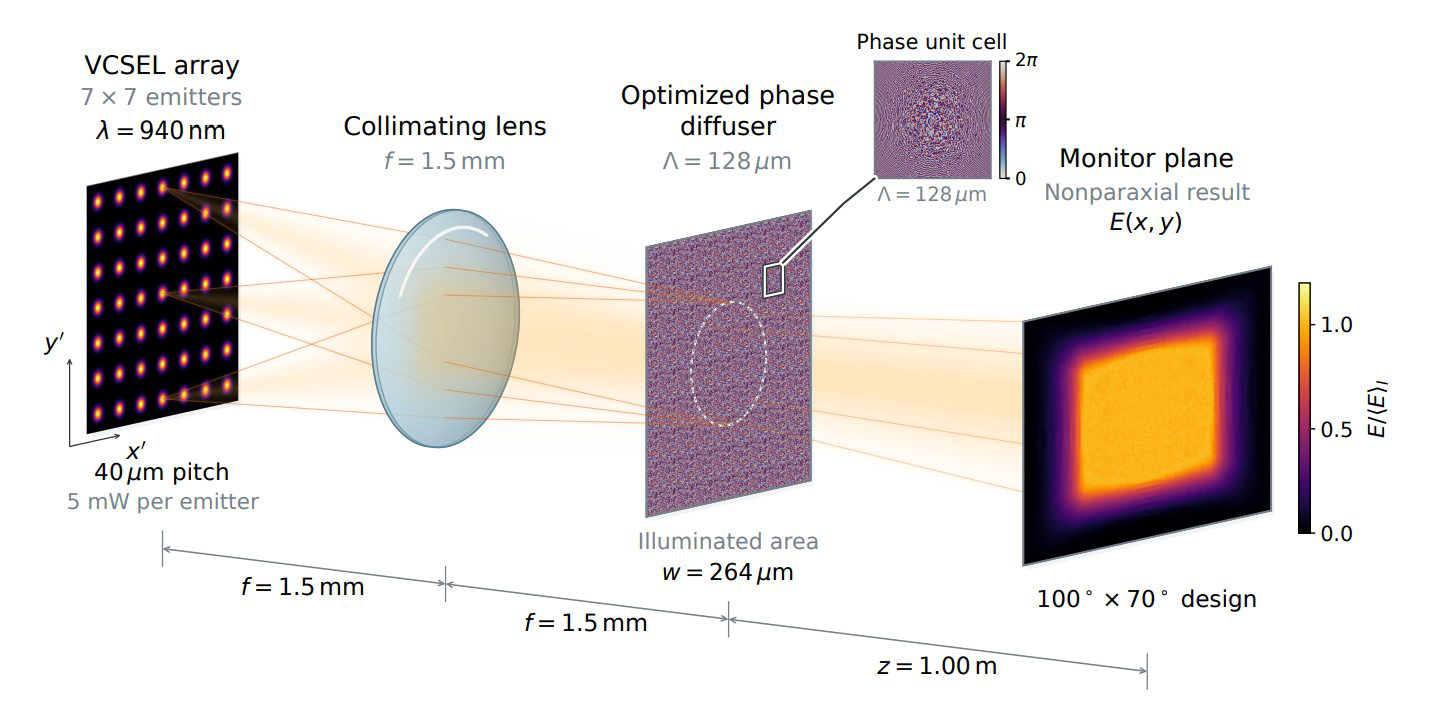

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import fft
import jax
jax.config.update("jax_enable_x64", True)

import diffractsim
diffractsim.set_backend("JAX")
from diffractsim import IncoherentLightSimulation, PeriodicGaussianPupil, m, mm, um, nm, W
from diffractsim.util.backend_functions import backend as bd
from vcsel_target import make_flattop_target

plt.rcParams["figure.dpi"] = 150

## 1. Set the illumination and starting phase

The $940\,\mathrm{nm}$ emitters sit in the front focal plane of a $1.5\,\mathrm{mm}$ collimator, with the diffuser in its back focal plane. Each emitter becomes a Gaussian spot in the angular radiance $L_{\mathrm{in}}(\alpha',\beta')$. Their contributions add incoherently: $49$ emitters at $5\,\mathrm{mW}$ supply $P_0=245\,\mathrm{mW}$.

All beams share a Gaussian envelope with $1/e^2$ intensity radius $w\simeq264.49\,\mu\mathrm{m}$. We write the pupil as

$$
\mathscr{P}(\xi,\eta)=
\exp\!\left[-\frac{\xi^2+\eta^2}{w^2}\right]e^{i\phi(\xi,\eta)},
\qquad
\phi=2\pi\,(G_{\sigma_f}\otimes\psi).
$$

The design variable $\psi$, stored in `waves`. A periodic Gaussian filter of width $\sigma_f=0.1\,\mu\mathrm{m}$ smooths it before conversion to radians. `PeriodicGaussianPupil` repeats the $128\,\mu\mathrm{m}$ phase cell under the Gaussian envelope. We start from a diverging lenslet with a smal perturbation

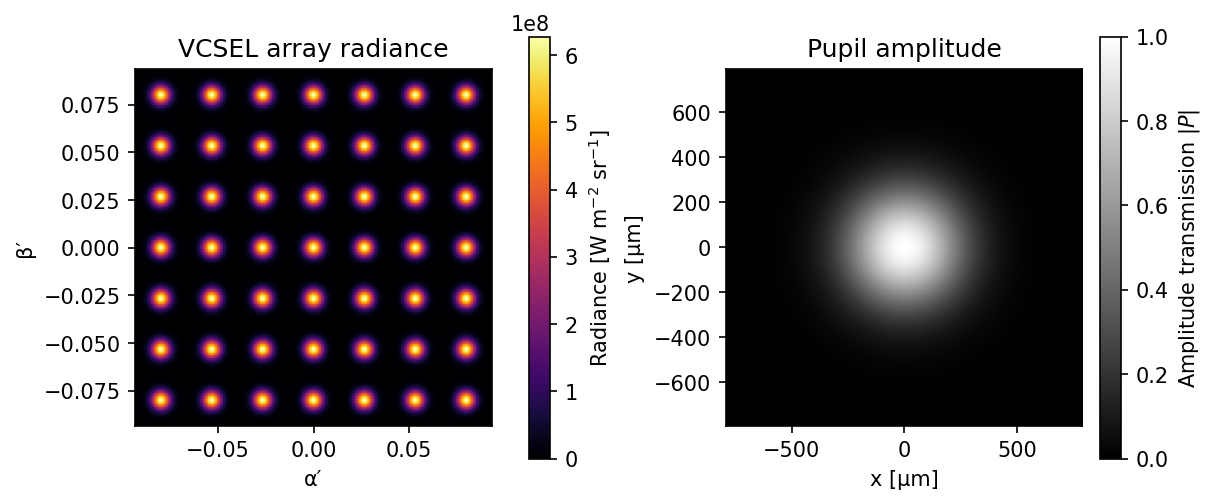

In [2]:
########################################################
# Setup pupil, initial phase  and VCSEL illumination
########################################################


# 1. Define the illumination and pupil, then inspect the starting design.
wavelength, period, phase_samples = 940*nm, 128*um, 2048
emitters, pitch, emitter_fwhm = 7, 40*um, 12*um  # Use diffractsim length units.
f_coll, divergence, emitter_power = 1.5*mm, 20.0, 5e-3*W
z2, field_degrees = 1*m, (100.0, 70.0)
filter_width, seed = 0.1*um, 1
samples_per_order, order_limit = 6, 1.12

# Set up the source geometry and radiance. Power/area is W/m² because
# the vendor uses picowatts and square micrometres internally.
beam_radius = f_coll*np.tan(np.deg2rad(divergence/2))
pupil_area, input_power = np.pi*beam_radius**2/2, emitters**2*emitter_power
source_sigma = emitter_fwhm/f_coll/np.sqrt(8*np.log(2))
lobe_sigma = np.hypot(source_sigma, wavelength/(2*np.pi*beam_radius))
source_positions = bd.asarray((np.arange(emitters)-(emitters-1)/2)*pitch/f_coll)
source_halfwidth = float(bd.max(abs(source_positions)))

def vcsel_source(alpha, beta, sigma=source_sigma):
    """Radiance of the collimated array; each emitter supplies emitter_power."""
    gx = bd.sum(bd.exp(-(alpha[..., None]-source_positions)**2/(2*sigma**2)), axis=-1)
    gy = bd.sum(bd.exp(-(beta[..., None]-source_positions)**2/(2*sigma**2)), axis=-1)
    return emitter_power/(pupil_area*2*bd.pi*sigma**2)*gx*gy




# Align the angular grid with the diffraction orders and leave room for the source.
order_spacing = wavelength/period
angular_step = order_spacing/samples_per_order
orders = int(np.ceil(order_limit/order_spacing))
guard = int(np.ceil((source_halfwidth+6*lobe_sigma)/angular_step))+2
angular_samples = fft.next_fast_len(2*(orders*samples_per_order+guard)+8, real=True)
sim_vcsel = IncoherentLightSimulation(wavelength, period, period, phase_samples, phase_samples)




##############################################################
# sim_vcsel contains the simulation object we are goint to use
##############################################################

sim_vcsel.set_angular_illumination(vcsel_source, paraxial=False,angular_samples=angular_samples, angular_limit=angular_samples*angular_step/2)


###############################
# set up the initial phase
###############################

# One Fourier grid for the phase filter and the smooth initial perturbation.
pixel_pitch = period/phase_samples
fx, fy = fft.rfftfreq(phase_samples, pixel_pitch), fft.fftfreq(phase_samples, pixel_pitch)
frequency_squared = fx[None, :]**2+fy[:, None]**2
phase_filter = bd.asarray(np.exp(-2*np.pi**2*filter_width**2*frequency_squared))

def vcsel_phase(waves):
    """Convert the filtered design variable from waves to phase in radians."""
    return 2*bd.pi*bd.fft.irfft2(bd.fft.rfft2(waves)*phase_filter, s=waves.shape)

# Lenslet start plus a smooth 0.15-wave perturbation.
u = (np.arange(phase_samples)-phase_samples/2+0.5)*pixel_pitch
edge = np.sin(np.deg2rad(np.asarray(field_degrees)/2))
initial = (0.90*edge[0]*u[None, :]**2+0.88*edge[1]*u[:, None]**2)/(wavelength*period)
noise = np.random.default_rng(seed).standard_normal((phase_samples, phase_samples))
noise_filter = np.exp(-2*np.pi**2*(1*um)**2*frequency_squared)
noise = fft.irfft2(fft.rfft2(noise)*noise_filter, s=noise.shape)
initial_waves = bd.asarray(initial+0.15*noise/noise.std())



####################
# Visualization
####################

initial_vcsel_phase = vcsel_phase(initial_waves)
initial_vcsel_pupil = PeriodicGaussianPupil(initial_vcsel_phase, period, beam_radius, order_limit)

pupil_view = IncoherentLightSimulation(wavelength, 6*beam_radius, 6*beam_radius, 512, 512)
source_span = 2*(source_halfwidth+4*source_sigma)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), layout="constrained")
sim_vcsel.plot_angular_illumination(source_extent_α=source_span, source_extent_β=source_span,
    samples=481, ax=axes[0], title="VCSEL array radiance")
pupil_view.plot_aperture(initial_vcsel_pupil, units=um, ax=axes[1], title="Pupil amplitude")
plt.show()

## 2. Build the objetive function $\mathcal{L}$ and optimize the phase

The extended source softens the edges of the illuminated field, so the target $T$ includes this gradual transition. As in Supplement S6.2, we divide the monitor into an interior $I$, an edge region $G$, and an exterior $O$. We normalize the irradiance by its mean in the interior, $s=\langle E\rangle_I$, and average the squared error separately over each region:

$$
\mathcal{L}=
\left\langle(E/s-T)^2\right\rangle_I+
\left\langle(E/s-T)^2\right\rangle_G+
0.3\left\langle(E/s-T)^2\right\rangle_O+
0.02(1-\eta_{\mathrm{FoI}}).
$$

The first three terms match the target shape and penalize unwanted light outside the field. The last term encourages more power to reach the desired field, where $\eta_{\mathrm{FoI}}=P_0^{-1}\int_{\mathrm{FoI}}E\,\mathrm{d}A$ is the fraction of incident power collected there. We measure the remaining variation in the interior using $U_{\mathrm{RMS}}=\sqrt{\langle(E/s-1)^2\rangle_I}$.

At each iteration, Adam updates the phase using the gradient of this loss, with the irradiance calculated from Eq. (24). We use `model="Fresnel", sampling="angular"` for the periodic Gaussian pupil. Switching to `model="ASM"` with the same angular sampling gives nearly identical results for this example.

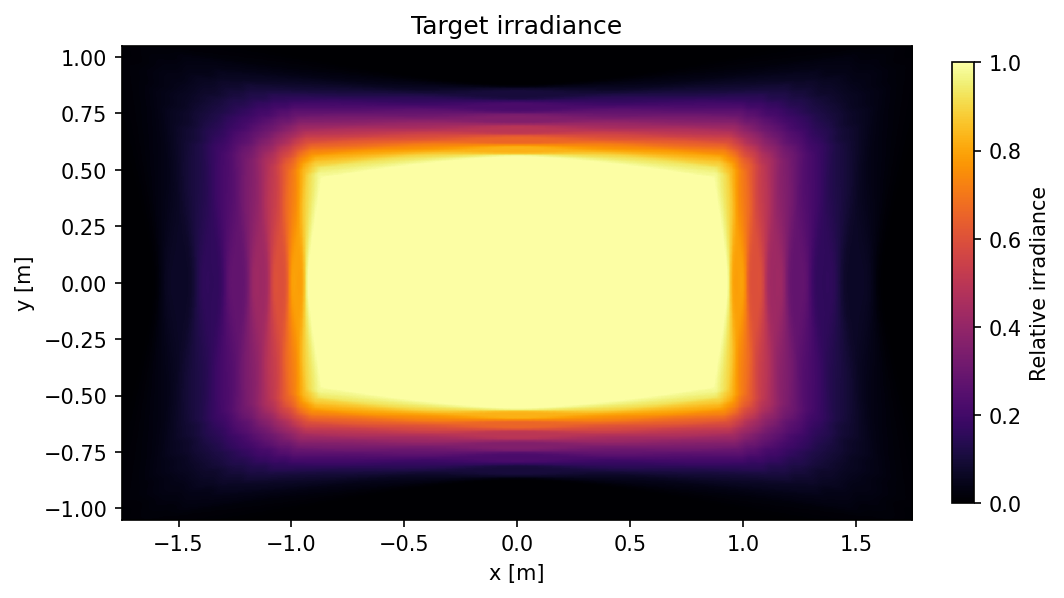

   0: loss=0.238184
 100: loss=0.005011
 200: loss=0.004084
 300: loss=0.003756
 400: loss=0.003598
 500: loss=0.003512
 600: loss=0.003463
 700: loss=0.003436
Collected power: 84.210% | RMS nonuniformity: 1.245%


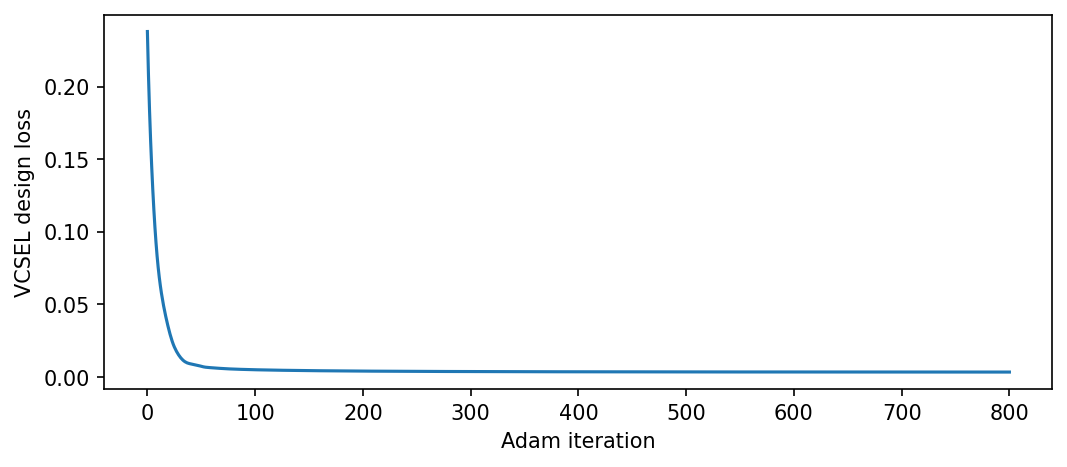

In [3]:
# 2. Build the target, optimize with Eq. (24), and plot the loss.
iterations, target_steps = 800, 60
spill_weight, power_weight = 0.3, 0.02
phase_step, final_step = 0.08, 0.008  # Adam steps in radians.

#################################
# Set up the target irradiance
#################################

screen_step = pitch/f_coll/10
vcsel_x = z2*np.arange(-1.75, 1.75+screen_step/2, screen_step)
vcsel_y = z2*np.arange(-1.05, 1.05+screen_step/2, screen_step)
target, interior, field = make_flattop_target(vcsel_x, vcsel_y, z2, field_degrees,angular_samples=angular_samples, angular_step=angular_step,source_kernel=lambda a, b: pupil_area*vcsel_source(a, b, sigma=lobe_sigma),input_power=input_power, iterations=target_steps)
pixel_area = (z2*screen_step)**2
exterior = (target <= 0.02) & ~interior
rolloff = ~(interior | exterior)

# Normalize fixed masks once, outside JIT: no large constant sums to compile.
interior_weights = interior/np.count_nonzero(np.asarray(interior))
loss_weights = (interior_weights + rolloff/np.count_nonzero(np.asarray(rolloff))+ spill_weight*exterior/np.count_nonzero(np.asarray(exterior)))

def get_vcsel_irradiance(phase):
    """The same optical model is used during optimization and for the final plot."""
    def optical_setup(F, z):
        F = F.add(PeriodicGaussianPupil(phase, period, beam_radius, order_limit))
        return F.zoom_propagate(z, [vcsel_x[0], vcsel_x[-1]], [vcsel_y[0], vcsel_y[-1]], Nx_mon=len(vcsel_x), Ny_mon=len(vcsel_y), model="Fresnel", sampling="angular")
    return sim_vcsel.get_irradiance(optical_setup, z2)[2]


#################################
# Set up the objetive function
#################################



def vcsel_loss(waves):
    """Match the target shape and reward power inside the desired field."""
    E = get_vcsel_irradiance(vcsel_phase(waves))
    mean = bd.sum(E*interior_weights)
    error = (E/mean-target)**2
    efficiency = bd.sum(E*field)*pixel_area/input_power
    loss = bd.sum(error*loss_weights) + power_weight*(1-efficiency)
    nonuniformity = bd.sqrt(bd.sum((E/mean-1)**2*interior_weights))
    return loss, bd.array([efficiency, nonuniformity])


# plot the target irradiance
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
sim_vcsel.plot_map(vcsel_x, vcsel_y, target, units=m, labels=("x [m]", "y [m]"),
    ax=ax, title="Target irradiance", colorbar_label="Relative irradiance", vmin=0, vmax=1)
plt.show()

# Start each run from the same pupil.
waves = initial_waves
first_moment, second_moment = bd.zeros_like(waves), bd.zeros_like(waves)

@jax.jit
def vcsel_adam_step(waves, first, second, iteration, step_size):
    """Apply the paper's Adam update to the phase design variable."""
    (loss, metrics), gradient = jax.value_and_grad(vcsel_loss, has_aux=True)(waves)
    b1, b2 = 0.9, 0.999
    first = b1*first+(1-b1)*gradient
    second = b2*second+(1-b2)*gradient**2
    rms = bd.sqrt(second/(1-b2**iteration))
    waves -= step_size*(first/(1-b1**iteration))/(rms+1e-12*rms.max()+1e-300)
    return waves, first, second, loss, metrics




#################################
# Run the optimization
#################################



vcsel_history = []
for step in range(iterations):
    step_size = (final_step+0.5*(phase_step-final_step)*(1+np.cos(np.pi*step/iterations)))/(2*np.pi)
    waves, first_moment, second_moment, loss, metrics = vcsel_adam_step(
        waves, first_moment, second_moment, float(step+1), step_size)
    vcsel_history.append(float(loss))
    if step % 100 == 0:
        print(f"{step:4d}: loss={float(loss):.6f}")

final_vcsel_phase = vcsel_phase(waves)
final_loss, metrics = jax.jit(vcsel_loss)(waves)
vcsel_history.append(float(final_loss))
print(f"Collected power: {100*float(metrics[0]):.3f}% | RMS nonuniformity: {100*float(metrics[1]):.3f}%")
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.plot(vcsel_history)
ax.set(xlabel="Adam iteration", ylabel="VCSEL design loss")
plt.show()

## 3. Inspect the optimized phase

This plot shows one period of the final phase. The optimizer works with the unwrapped variable $\psi$; wrapping the displayed phase modulo $2\pi$ leaves the pupil transmission $e^{i\phi}$ unchanged.

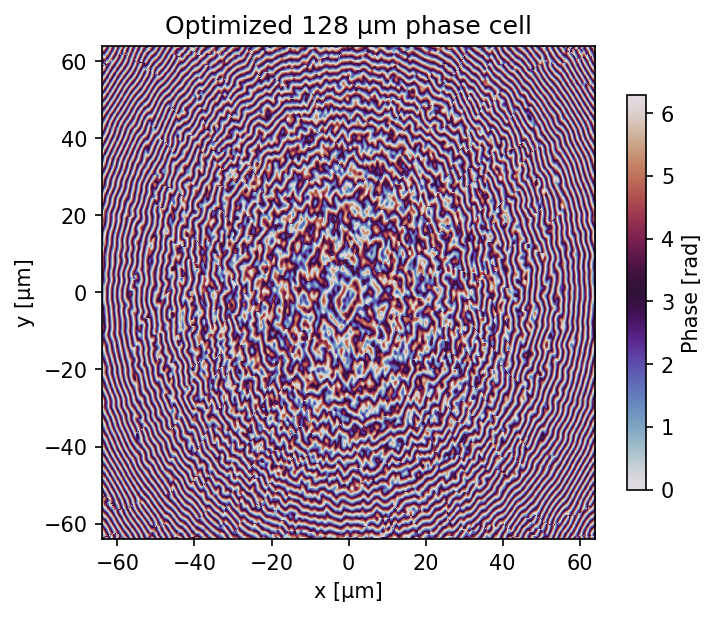

<Axes: title={'center': 'Optimized 128 µm phase cell'}, xlabel='x [µm]', ylabel='y [µm]'>

In [4]:
# 3. Inspect the optimized phase.
sim_vcsel.plot_aperture(bd.exp(1j*final_vcsel_phase), phase=True, units=um,
    title=f"Optimized {period/um:g} µm phase cell")

## 4. Compare the final irradiance with the target

We evaluate the optimized pupil with the same forward model used in the loss. The full monitor map shows irradiance in $\mathrm{W\,m^{-2}}$. The central profile then compares $E/s$ with $T$, using the same interior mean as the optimization.

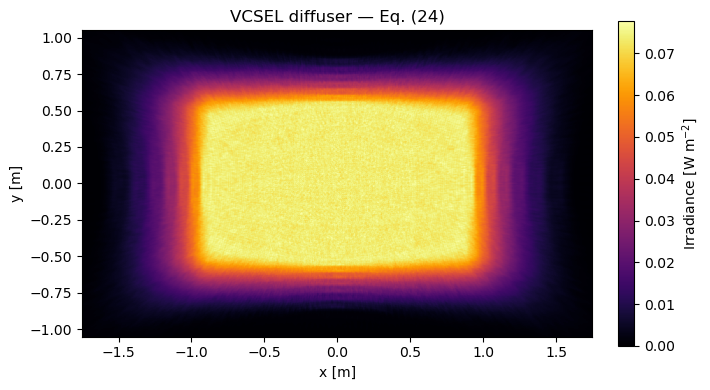

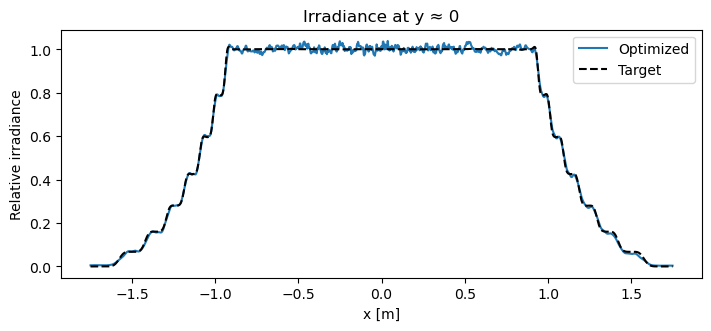

In [5]:
# 4. Plot the full monitor and compare the central profiles.
E_vcsel = get_vcsel_irradiance(final_vcsel_phase)
sim_vcsel.plot_irradiance(E_vcsel, units=m, cmap="inferno", figsize=(7, 4.2),
    text="VCSEL diffuser — Eq. (24)")

row = np.argmin(abs(vcsel_y))  # Monitor row closest to y = 0.
mean = bd.sum(E_vcsel*interior_weights)
fig, ax = plt.subplots(figsize=(7, 3.2), layout="constrained")
ax.plot(vcsel_x/m, np.asarray(E_vcsel[row]/mean), label="Optimized")
ax.plot(vcsel_x/m, np.asarray(target[row]), "k--", label="Target")
ax.set(xlabel="x [m]", ylabel="Relative irradiance", title="Irradiance at y ≈ 0")
ax.legend()
plt.show()

# Paper results verification
Here we reproduce the results reported in the paper:

## 5. Reproduce Fig. 6(b–f): matched designs and RS evaluation

Four models optimize the same target from the same starting phase:

| Model | Irradiance calculation during design |
|---|---|
| Eq. (8) | Translate the paraxial response across the monitor. |
| Coordinate-corrected Eq. (8) | Map the central response into direction cosines, then translate it on the monitor. Omit $c^4$ from the shape; retain it in the power integral. |
| Eq. (22) | Convolve in direction cosines and apply $c^4/z_2^2$. |
| Eq. (24) | Also include the finite-distance Gaussian-order correction of Supplement S6.3. |

After optimization,  with the same outgoing RS reference we evaluate every
design. Only then do we divide each image by its own interior mean for the
figure. Efficiency and model errors use the absolute irradiance.

The defaults reproduce the first matched start in Fig. 6 and Table S1:
2048 × 2048 phase samples and 800 Adam steps for each model. Change
`fig6_seeds` to `(1, 2, 3)` for the paper's three-start comparison.
Completed designs and RS images are cached; rerunning the cells reuses them
only when their settings and helper code match. Full optimization is costly
on CPU; JAX also supports an appropriately configured GPU.

Panel (c) displays the Eq. (24) design. The independently optimized Eq. (22)
design appears separately in the metrics and profile; the shared panel label
follows the paper and indicates their close agreement in this geometry.


In [7]:
# Fig. 6.1 — Imports and physical parameters; independent of all earlier cells.
from pathlib import Path
import hashlib
import json
import time
import numpy as np
from scipy import fft
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from IPython.display import display, Markdown
from vcsel_target import make_flattop_target
from vcsel_fig6 import prepare_forward, prepare_rs_reference

fig6_seeds = (1,)
fig6_models = ("eq8", "mapped8", "eq22", "eq24")
fig6_labels = {"eq8": "Eq. (8), paraxial", "mapped8": "Eq. (8), coordinate-corrected",
               "eq22": "Eq. (22)", "eq24": "Eq. (24)"}
fig6_parameters = dict(wavelength=0.94e-6, period=128e-6, phase_samples=2048,
    emitters=7, pitch=40e-6, emitter_fwhm=12e-6, focal_length=1.5e-3,
    divergence_degrees=20.0, emitter_power=5e-3, z=1.0,
    field_degrees=(100.0, 70.0), filter_width=0.1e-6,
    samples_per_order=6, order_limit=1.12, iterations=800,
    first_step=0.08, last_step=0.008, target_iterations=60)
fig6_p = fig6_parameters
fig6_radius = fig6_p["focal_length"]*np.tan(np.deg2rad(fig6_p["divergence_degrees"]/2))
fig6_positions = (np.arange(fig6_p["emitters"])-(fig6_p["emitters"]-1)/2)*fig6_p["pitch"]/fig6_p["focal_length"]
fig6_sigma = fig6_p["emitter_fwhm"]/fig6_p["focal_length"]/np.sqrt(8*np.log(2))
fig6_lobe_sigma = np.hypot(fig6_sigma, fig6_p["wavelength"]/(2*np.pi*fig6_radius))
fig6_power = fig6_p["emitters"]**2*fig6_p["emitter_power"]
fig6_step = fig6_p["pitch"]/fig6_p["focal_length"]/10
fig6_x = fig6_p["z"]*np.arange(-1.75, 1.75+fig6_step/2, fig6_step)
fig6_y = fig6_p["z"]*np.arange(-1.05, 1.05+fig6_step/2, fig6_step)
fig6_pixel_area = (fig6_p["z"]*fig6_step)**2
fig6_c4 = (1+(fig6_x[None, :]/fig6_p["z"])**2+(fig6_y[:, None]/fig6_p["z"])**2)**-2
fig6_settings = dict(x=fig6_x, y=fig6_y, z=fig6_p["z"], wavelength=fig6_p["wavelength"],
    period=fig6_p["period"], radius=fig6_radius, source_positions=fig6_positions,
    source_sigma=fig6_sigma, emitter_power=fig6_p["emitter_power"],
    samples_per_order=fig6_p["samples_per_order"], order_limit=fig6_p["order_limit"])

fig6_code_hash = hashlib.sha256(Path("vcsel_fig6.py").read_bytes()+Path("vcsel_target.py").read_bytes()).hexdigest()
fig6_signature = hashlib.sha256((json.dumps(fig6_parameters, sort_keys=True)+fig6_code_hash).encode()).hexdigest()[:16]
fig6_folder = Path("fig6_results")/fig6_signature
fig6_folder.mkdir(parents=True, exist_ok=True)
print(f"{jax.devices()[0]} | {fig6_p['phase_samples']}² phase samples | {fig6_p['iterations']} Adam steps/model")
print(f"Incident power: {1000*fig6_power:.1f} mW; Gaussian radius: {1e6*fig6_radius:.2f} µm")
print(f"Cache: {fig6_folder}")


cuda:0 | 2048² phase samples | 800 Adam steps/model
Incident power: 245.0 mW; Gaussian radius: 264.49 µm
Cache: fig6_results/abc3a0f8e6e4bfea


In [8]:
# Fig. 6.2 — One source-softened target, shared by all four designs.
fig6_du = fig6_p["wavelength"]/fig6_p["period"]
fig6_h = fig6_du/fig6_p["samples_per_order"]
fig6_guard = int(np.ceil((abs(fig6_positions).max()+6*fig6_lobe_sigma)/fig6_h))+2
fig6_angular_samples = fft.next_fast_len(2*(int(np.ceil(fig6_p["order_limit"]/fig6_du))*fig6_p["samples_per_order"]+fig6_guard)+8, real=True)

def fig6_source_kernel(alpha, beta):
    """Power density of the array, including the Gaussian envelope's lobe width."""
    gx = np.exp(-(alpha[..., None]+fig6_positions)**2/(2*fig6_lobe_sigma**2)).sum(-1)
    gy = np.exp(-(beta[..., None]+fig6_positions)**2/(2*fig6_lobe_sigma**2)).sum(-1)
    return fig6_p["emitter_power"]*gx*gy/(2*np.pi*fig6_lobe_sigma**2)

fig6_target, fig6_interior, fig6_field = make_flattop_target(
    fig6_x, fig6_y, fig6_p["z"], fig6_p["field_degrees"],
    angular_samples=fig6_angular_samples, angular_step=fig6_h,
    source_kernel=fig6_source_kernel, input_power=fig6_power,
    iterations=fig6_p["target_iterations"])
fig6_exterior = (fig6_target <= 0.02) & ~fig6_interior
fig6_rolloff = ~(fig6_interior | fig6_exterior)
fig6_interior_weights = jnp.asarray(fig6_interior/fig6_interior.sum())
fig6_loss_weights = jnp.asarray(fig6_interior/fig6_interior.sum()
    +fig6_rolloff/fig6_rolloff.sum()+0.3*fig6_exterior/fig6_exterior.sum())
print(f"Target interior RMS variation: {100*fig6_target[fig6_interior].std()/fig6_target[fig6_interior].mean():.4f}%")


Target interior RMS variation: 0.1306%


The objective and Adam update are the ones used above and in Supplement S6.2.
The exterior target is at most 0.02; the companion implementation retains
that small target tail in its squared-error term. The coordinate-corrected
model uses $c^4$ only for its power reward. Fixed source kernels and monitor
interpolation weights are prepared once; only the phase-dependent operations
are differentiated at each step.

In [9]:
# Fig. 6.3 — Starting phases, loss, and a reusable Adam step.
fig6_n = fig6_p["phase_samples"]
fig6_dx = fig6_p["period"]/fig6_n
fig6_fx, fig6_fy = fft.rfftfreq(fig6_n, fig6_dx), fft.fftfreq(fig6_n, fig6_dx)
fig6_frequency_squared = fig6_fx[None, :]**2+fig6_fy[:, None]**2
fig6_filter = jnp.asarray(np.exp(-2*np.pi**2*fig6_p["filter_width"]**2*fig6_frequency_squared))

def fig6_phase(variable):
    """Smooth the periodic variable and convert waves to radians."""
    return 2*jnp.pi*jnp.fft.irfft2(jnp.fft.rfft2(variable)*fig6_filter, s=variable.shape)

def fig6_start(seed):
    """Use the same lenslet and smooth perturbation for every model."""
    u = (np.arange(fig6_n)-fig6_n/2+0.5)*fig6_dx
    edge = np.sin(np.deg2rad(np.asarray(fig6_p["field_degrees"])/2))
    lenslet = (0.90*edge[0]*u[None, :]**2+0.88*edge[1]*u[:, None]**2)/(fig6_p["wavelength"]*fig6_p["period"])
    noise = np.random.default_rng(seed).standard_normal((fig6_n, fig6_n))
    noise = fft.irfft2(fft.rfft2(noise)*np.exp(-2*np.pi**2*(1e-6)**2*fig6_frequency_squared), s=noise.shape)
    return jnp.asarray(lenslet+0.15*noise/noise.std())

def fig6_objective(forward, model):
    """Make the common shape-and-power loss for one propagation model."""
    def objective(variable):
        image = forward(fig6_phase(variable))
        mean = jnp.sum(image*fig6_interior_weights)
        error = (image/mean-fig6_target)**2
        power_image = image*fig6_c4 if model == "mapped8" else image
        efficiency = jnp.sum(power_image*fig6_field)*fig6_pixel_area/fig6_power
        loss = jnp.sum(error*fig6_loss_weights)+0.02*(1-efficiency)
        rms = jnp.sqrt(jnp.sum((image/mean-1)**2*fig6_interior_weights))
        return loss, jnp.array([efficiency, rms])
    return objective

def fig6_adam(objective):
    """Prepare one Adam update, with gradients supplied by JAX."""
    @jax.jit
    def update(variable, first, second, step, rate):
        (loss, metrics), gradient = jax.value_and_grad(objective, has_aux=True)(variable)
        first, second = 0.9*first+0.1*gradient, 0.999*second+0.001*gradient**2
        rms = jnp.sqrt(second/(1-0.999**step))
        variable -= rate*(first/(1-0.9**step))/(rms+1e-12*rms.max()+1e-300)
        return variable, first, second, loss, metrics
    return update

def fig6_save(path, **arrays):
    """Replace a cache only after its complete contents have been written."""
    temporary = path.with_suffix(".tmp")
    with temporary.open("wb") as stream:
        np.savez_compressed(stream, **arrays)
    temporary.replace(path)


In [10]:
# Fig. 6.4 — Optimize each model, or load its matching completed run.
fig6_designs = {}
for fig6_seed in fig6_seeds:
    for fig6_model in fig6_models:
        fig6_path = fig6_folder/f"design_{fig6_model}_seed{fig6_seed}.npz"
        if fig6_path.exists():
            with np.load(fig6_path, allow_pickle=False) as saved:
                fig6_designs[fig6_seed, fig6_model] = {key: saved[key] for key in saved.files}
            print(f"Loaded {fig6_labels[fig6_model]}, seed {fig6_seed}")
            continue
        fig6_forward = prepare_forward(fig6_model, **fig6_settings)
        fig6_loss_function = fig6_objective(fig6_forward, fig6_model)
        fig6_update = fig6_adam(fig6_loss_function)
        fig6_progress_path = fig6_folder/f"progress_{fig6_model}_seed{fig6_seed}.npz"
        if fig6_progress_path.exists():
            with np.load(fig6_progress_path, allow_pickle=False) as saved:
                fig6_variable = jnp.asarray(saved["variable"])
                fig6_first, fig6_second = jnp.asarray(saved["first"]), jnp.asarray(saved["second"])
                fig6_history = saved["history"].tolist()
            print(f"Resuming {fig6_model} after {len(fig6_history)} steps")
        else:
            fig6_variable = fig6_start(fig6_seed)
            fig6_first, fig6_second = jnp.zeros_like(fig6_variable), jnp.zeros_like(fig6_variable)
            fig6_history = []
        fig6_clock = time.perf_counter()
        for fig6_step_number in range(len(fig6_history), fig6_p["iterations"]):
            fig6_rate = (fig6_p["last_step"]+0.5*(fig6_p["first_step"]-fig6_p["last_step"])
                *(1+np.cos(np.pi*fig6_step_number/fig6_p["iterations"])))/(2*np.pi)
            fig6_variable, fig6_first, fig6_second, fig6_loss_value, fig6_metrics = fig6_update(
                fig6_variable, fig6_first, fig6_second, float(fig6_step_number+1), fig6_rate)
            fig6_history.append(float(fig6_loss_value))
            if fig6_step_number % 100 == 0:
                print(f"{fig6_model}, seed {fig6_seed}, step {fig6_step_number:3d}: loss={float(fig6_loss_value):.6f}")
            if (fig6_step_number+1) % 100 == 0:
                fig6_save(fig6_progress_path, variable=fig6_variable, first=fig6_first,
                          second=fig6_second, history=np.asarray(fig6_history))
        fig6_final_phase = fig6_phase(fig6_variable)
        fig6_final_loss, fig6_metrics = jax.jit(fig6_loss_function)(fig6_variable)
        fig6_history.append(float(fig6_final_loss))
        fig6_record = dict(phase=np.asarray(fig6_final_phase),
            predicted=np.asarray(fig6_forward(fig6_final_phase)),
            history=np.asarray(fig6_history), metrics=np.asarray(fig6_metrics))
        fig6_save(fig6_path, **fig6_record)
        fig6_progress_path.unlink(missing_ok=True)
        fig6_designs[fig6_seed, fig6_model] = fig6_record
        print(f"Finished {fig6_model}: predicted RMS={100*float(fig6_metrics[1]):.3f}%, "
              f"{time.perf_counter()-fig6_clock:.0f} s")
        del fig6_forward, fig6_loss_function, fig6_update, fig6_variable, fig6_first, fig6_second
        jax.clear_caches()


eq8, seed 1, step   0: loss=0.370835
eq8, seed 1, step 100: loss=0.004305
eq8, seed 1, step 200: loss=0.003581
eq8, seed 1, step 300: loss=0.003303
eq8, seed 1, step 400: loss=0.003162
eq8, seed 1, step 500: loss=0.003084
eq8, seed 1, step 600: loss=0.003041
eq8, seed 1, step 700: loss=0.003017
Finished eq8: predicted RMS=1.048%, 59 s
mapped8, seed 1, step   0: loss=0.067708
mapped8, seed 1, step 100: loss=0.001941
mapped8, seed 1, step 200: loss=0.001600
mapped8, seed 1, step 300: loss=0.001473
mapped8, seed 1, step 400: loss=0.001415
mapped8, seed 1, step 500: loss=0.001385
mapped8, seed 1, step 600: loss=0.001369
mapped8, seed 1, step 700: loss=0.001360
Finished mapped8: predicted RMS=0.889%, 65 s
eq22, seed 1, step   0: loss=0.238188
eq22, seed 1, step 100: loss=0.005011
eq22, seed 1, step 200: loss=0.004085
eq22, seed 1, step 300: loss=0.003757
eq22, seed 1, step 400: loss=0.003599
eq22, seed 1, step 500: loss=0.003512
eq22, seed 1, step 600: loss=0.003464
eq22, seed 1, step 700: 

### A common outgoing RS evaluation

The illumination is already a prescribed collimated mixture, so there is
no finite source-to-pupil RS leg in this example. The reference uses the
outgoing kernel of Eq. (25), including its amplitude, obliquity, phase and
$1/(kR)$ term.



In [12]:
# Fig. 6.5 — Prepare the RS quadrature once, then evaluate all designs.
fig6_rs_controls = dict(monitor_order=7, envelope_samples=512,
                        pair_radius=1, pair_tolerance=1e-10, interpolation_order=5)
fig6_rs_signature = hashlib.sha256(json.dumps(fig6_rs_controls, sort_keys=True).encode()).hexdigest()[:10]
fig6_rs_images = {}
fig6_reference = None
for fig6_seed in fig6_seeds:
    for fig6_model in fig6_models:
        fig6_rs_path = fig6_folder/f"rs_{fig6_model}_seed{fig6_seed}_{fig6_rs_signature}.npz"
        if fig6_rs_path.exists():
            with np.load(fig6_rs_path, allow_pickle=False) as saved:
                fig6_rs_images[fig6_seed, fig6_model] = saved["image"]
                fig6_rs_details = json.loads(str(saved["details"]))
            print(f"Loaded RS: {fig6_model}, seed {fig6_seed}")
            continue
        if fig6_reference is None:
            fig6_reference, fig6_rs_details = prepare_rs_reference(
                **fig6_settings, **fig6_rs_controls, progress=True)
        fig6_image = np.asarray(fig6_reference(fig6_designs[fig6_seed, fig6_model]["phase"]))
        if not np.isfinite(fig6_image).all():
            raise ValueError("The RS image contains non-finite values.")
        fig6_rs_images[fig6_seed, fig6_model] = fig6_image
        fig6_save(fig6_rs_path, image=fig6_image, details=json.dumps(fig6_rs_details))
        print(f"RS complete: {fig6_model}, seed {fig6_seed}")
print("RS numerical settings:", fig6_rs_details)


RS kernels: 1/7 monitor rows
RS kernels: 2/7 monitor rows
RS kernels: 3/7 monitor rows
RS kernels: 4/7 monitor rows
RS kernels: 5/7 monitor rows
RS kernels: 6/7 monitor rows
RS kernels: 7/7 monitor rows
RS complete: eq8, seed 1
RS complete: mapped8, seed 1
RS complete: eq22, seed 1
RS complete: eq24, seed 1
RS numerical settings: {'monitor_order': 7, 'envelope_samples': 512, 'angular_samples': 2025, 'samples_per_order': 6, 'pair_radius': 1, 'interpolation_order': 5, 'interpolation_bound_factor': 4, 'retained_node_pair_kernels': 147, 'skipped_pair_absolute_bound_W_m2': 3.6412458420775673e-13}


In [13]:
# Fig. 6.6 — Measured uniformity, collected power, and absolute-scale errors.
def fig6_measure(image):
    """Measure the interior variation and power in the nominal field."""
    image = np.asarray(image)
    values = image[fig6_interior]
    return dict(rms_percent=100*values.std()/values.mean(),
        efficiency_percent=100*image[fig6_field].sum()*fig6_pixel_area/fig6_power,
        interior_mean_W_m2=float(values.mean()))

fig6_paper_values = {"eq8": (32.287, 47.259), "mapped8": (33.904, 92.150),
                    "eq22": (1.272, 84.210), "eq24": (1.273, 84.210)}
fig6_results = []
fig6_lines = ["| Design | Seed | Predicted RMS [%] | RS RMS [%] | RS efficiency [%] |",
              "|---|---:|---:|---:|---:|"]
for fig6_seed in fig6_seeds:
    for fig6_model in fig6_models:
        fig6_record = fig6_designs[fig6_seed, fig6_model]
        fig6_prediction = fig6_measure(fig6_record["predicted"])
        fig6_measured = fig6_measure(fig6_rs_images[fig6_seed, fig6_model])
        fig6_results.append(dict(model=fig6_model, seed=int(fig6_seed),
            predicted_rms_percent=fig6_prediction["rms_percent"], **fig6_measured))
        fig6_lines.append(f"| {fig6_labels[fig6_model]} | {fig6_seed} | "
            f"{fig6_prediction['rms_percent']:.3f} | {fig6_measured['rms_percent']:.3f} | "
            f"{fig6_measured['efficiency_percent']:.3f} |")
display(Markdown("\n".join(fig6_lines)))

fig6_selected_seed = fig6_seeds[0]
fig6_final = fig6_designs[fig6_selected_seed, "eq24"]["phase"]
fig6_reference_image = fig6_rs_images[fig6_selected_seed, "eq24"]
fig6_errors = {}
for fig6_model in ("eq22", "eq24"):
    fig6_prediction = np.asarray(prepare_forward(fig6_model, **fig6_settings)(fig6_final))
    fig6_errors[fig6_model] = 100*np.linalg.norm(fig6_prediction-fig6_reference_image)/np.linalg.norm(fig6_reference_image)
    print(f"{fig6_labels[fig6_model]} versus RS for the Eq. (24) design: {fig6_errors[fig6_model]:.5f}% relative L2")
print("Paper Table S1 (RS RMS %, efficiency %):", fig6_paper_values)
print("The table above contains newly calculated values; the paper values are comparison references.")
(fig6_folder/"metrics.json").write_text(json.dumps(dict(parameters=fig6_parameters,
    results=fig6_results, eq24_design_L2_percent=fig6_errors,
    paper_table_S1=fig6_paper_values, rs_settings=fig6_rs_details), indent=2))


| Design | Seed | Predicted RMS [%] | RS RMS [%] | RS efficiency [%] |
|---|---:|---:|---:|---:|
| Eq. (8), paraxial | 1 | 1.048 | 32.287 | 47.259 |
| Eq. (8), coordinate-corrected | 1 | 0.889 | 33.904 | 92.150 |
| Eq. (22) | 1 | 1.246 | 1.272 | 84.210 |
| Eq. (24) | 1 | 1.246 | 1.272 | 84.210 |

Eq. (22) versus RS for the Eq. (24) design: 0.04789% relative L2
Eq. (24) versus RS for the Eq. (24) design: 0.04933% relative L2
Paper Table S1 (RS RMS %, efficiency %): {'eq8': (32.287, 47.259), 'mapped8': (33.904, 92.15), 'eq22': (1.272, 84.21), 'eq24': (1.273, 84.21)}
The table above contains newly calculated values; the paper values are comparison references.


2127

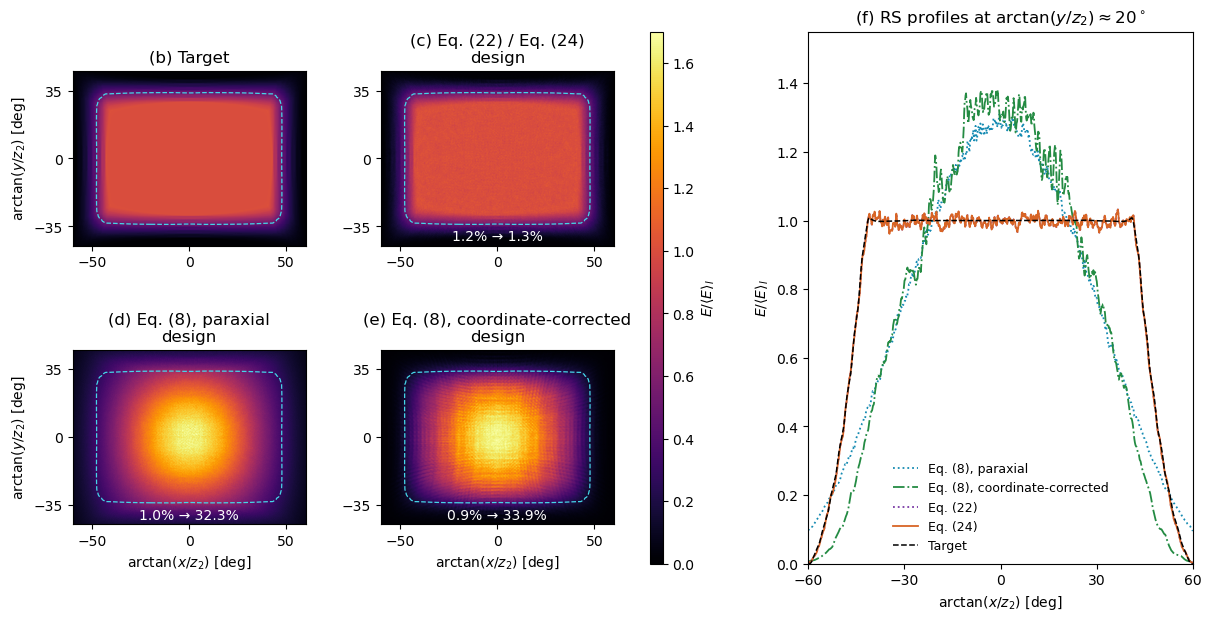

In [14]:
# Fig. 6.7 — Panels b–f, with common map limits and each design's interior mean.
from matplotlib.colors import Normalize
fig6_angles_x = np.degrees(np.arctan(fig6_x/fig6_p["z"]))
fig6_angles_y = np.degrees(np.arctan(fig6_y/fig6_p["z"]))
fig6_relative = {name: fig6_rs_images[fig6_selected_seed, name]/
    fig6_rs_images[fig6_selected_seed, name][fig6_interior].mean() for name in fig6_models}
fig6_target_relative = fig6_target/fig6_target[fig6_interior].mean()
fig6_figure = plt.figure(figsize=(12.0, 6.1), layout="constrained")
fig6_grid = fig6_figure.add_gridspec(2, 4, width_ratios=[1, 1, 0.055, 1.65], wspace=0.12)
fig6_map_axes = [fig6_figure.add_subplot(fig6_grid[0, 0]),
    fig6_figure.add_subplot(fig6_grid[0, 1]), fig6_figure.add_subplot(fig6_grid[1, 0]),
    fig6_figure.add_subplot(fig6_grid[1, 1])]
fig6_color_axis = fig6_figure.add_subplot(fig6_grid[:, 2])
fig6_profile_axis = fig6_figure.add_subplot(fig6_grid[:, 3])
fig6_norm = Normalize(0, 1.7)
fig6_panels = [("b", "Target", None, fig6_target_relative),
    ("c", "Eq. (22) / Eq. (24)\ndesign", "eq24", fig6_relative["eq24"]),
    ("d", "Eq. (8), paraxial\ndesign", "eq8", fig6_relative["eq8"]),
    ("e", "Eq. (8), coordinate-corrected\ndesign", "mapped8", fig6_relative["mapped8"])]
for fig6_ax, (fig6_letter, fig6_title, fig6_model, fig6_map) in zip(fig6_map_axes, fig6_panels):
    fig6_artist = fig6_ax.pcolormesh(fig6_angles_x, fig6_angles_y, fig6_map,
        shading="auto", cmap="inferno", norm=fig6_norm, rasterized=True)
    fig6_ax.contour(fig6_angles_x, fig6_angles_y, fig6_target, levels=[0.5],
        colors=["#45d6e8"], linestyles="--", linewidths=0.9)
    fig6_ax.set(title=f"({fig6_letter}) {fig6_title}", xlim=(-60, 60), ylim=(-45, 45),
        xticks=(-50, 0, 50), yticks=(-35, 0, 35), aspect="equal")
    if fig6_model is not None:
        fig6_predicted_rms = fig6_measure(fig6_designs[fig6_selected_seed, fig6_model]["predicted"])["rms_percent"]
        fig6_rs_rms = fig6_measure(fig6_rs_images[fig6_selected_seed, fig6_model])["rms_percent"]
        fig6_ax.text(0.5, 0.03, f"{fig6_predicted_rms:.1f}% → {fig6_rs_rms:.1f}%",
            transform=fig6_ax.transAxes, ha="center", color="white", fontsize=10)
for fig6_ax in fig6_map_axes[2:]: fig6_ax.set_xlabel(r"$\arctan(x/z_2)$ [deg]")
for fig6_ax in fig6_map_axes[::2]: fig6_ax.set_ylabel(r"$\arctan(y/z_2)$ [deg]")
fig6_figure.colorbar(fig6_artist, cax=fig6_color_axis, label=r"$E/\langle E\rangle_I$")

fig6_row = int(np.argmin(abs(fig6_angles_y-20)))
fig6_styles = {"eq8": ("#168bb2", ":"), "mapped8": ("#248b43", "-."),
               "eq22": ("#7a39a5", ":"), "eq24": ("#d86425", "-")}
for fig6_model in fig6_models:
    fig6_color, fig6_style = fig6_styles[fig6_model]
    fig6_profile_axis.plot(fig6_angles_x, fig6_relative[fig6_model][fig6_row],
        color=fig6_color, linestyle=fig6_style, linewidth=1.3, label=fig6_labels[fig6_model])
fig6_profile_axis.plot(fig6_angles_x, fig6_target_relative[fig6_row], "k--", linewidth=1.1, label="Target")
fig6_profile_axis.set(title=r"(f) RS profiles at $\arctan(y/z_2)\approx20^\circ$",
    xlabel=r"$\arctan(x/z_2)$ [deg]", ylabel=r"$E/\langle E\rangle_I$",
    xlim=(-60, 60), ylim=(0, 1.55), xticks=(-60, -30, 0, 30, 60))
fig6_profile_axis.legend(loc="lower center", frameon=False, fontsize=9)
fig6_figure.savefig(fig6_folder/"Fig6_b_f.png", dpi=200)
plt.show()


### Numerical refinement checks and the optimized phase

The next cell checks the Eq. (24) design at a subset of the original monitor
pixels, including both monitor endpoints. It refines the monitor-node
interpolation, envelope quadrature, neighboring-order sum, and angular grid
**one at a time**. 

The last cell shows each optimized cell and its loss history. 


RS refinements below compare sampled detector pixels on the absolute scale:

| Refinement | Relative L2 change [%] |
|---|---:|
| `{'monitor_order': 9}` | 0.000130 |
| `{'envelope_samples': 1024}` | 0.000000 |
| `{'pair_radius': 2}` | 0.000000 |
| `{'samples_per_order': 12}` | 0.001651 |


In [17]:
# Fig. 6.8 — Optional RS convergence checks on matching detector pixels.
fig6_run_refinement = False
if fig6_run_refinement:
    fig6_ix = np.unique(np.r_[np.arange(0, len(fig6_x), 48), len(fig6_x)-1])
    fig6_iy = np.unique(np.r_[np.arange(0, len(fig6_y), 48), len(fig6_y)-1])
    fig6_check_settings = dict(fig6_settings, x=fig6_x[fig6_ix], y=fig6_y[fig6_iy])
    fig6_baseline = fig6_reference_image[np.ix_(fig6_iy, fig6_ix)]
    fig6_refinements = [dict(monitor_order=9), dict(envelope_samples=1024),
                        dict(pair_radius=2), dict(samples_per_order=12)]
    fig6_refinement_results = {}
    for fig6_change in fig6_refinements:
        fig6_options = dict(fig6_check_settings, **fig6_rs_controls)
        fig6_options.update(fig6_change)
        fig6_refined, fig6_detail = prepare_rs_reference(**fig6_options)
        fig6_values = np.asarray(fig6_refined(fig6_final))
        fig6_error = 100*np.linalg.norm(fig6_values-fig6_baseline)/np.linalg.norm(fig6_baseline)
        fig6_refinement_results[str(fig6_change)] = fig6_error
        print(f"{fig6_change}: {fig6_error:.6f}% relative L2 change")
    (fig6_folder/"refinement.json").write_text(json.dumps(fig6_refinement_results, indent=2))


{'monitor_order': 9}: 0.000130% relative L2 change
{'envelope_samples': 1024}: 0.000000% relative L2 change
{'pair_radius': 2}: 0.000000% relative L2 change
{'samples_per_order': 12}: 0.001651% relative L2 change


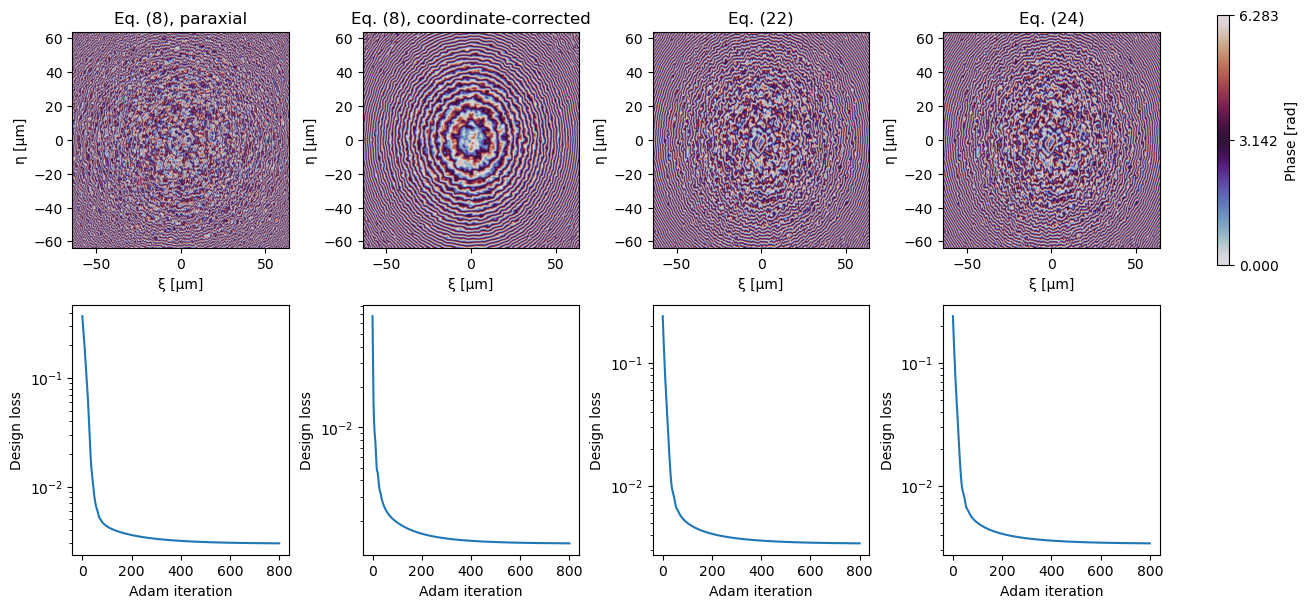

In [18]:
# Fig. 6.9 — Inspect all four phase cells and their loss histories.
fig6_phase_figure, fig6_phase_axes = plt.subplots(2, 4, figsize=(13, 6), layout="constrained")
fig6_half_period = fig6_p["period"]*1e6/2
for fig6_col, fig6_model in enumerate(fig6_models):
    fig6_record = fig6_designs[fig6_selected_seed, fig6_model]
    fig6_phase_artist = fig6_phase_axes[0, fig6_col].imshow(
        np.mod(fig6_record["phase"], 2*np.pi), origin="lower", cmap="twilight",
        vmin=0, vmax=2*np.pi, extent=[-fig6_half_period, fig6_half_period]*2)
    fig6_phase_axes[0, fig6_col].set(title=fig6_labels[fig6_model], xlabel="ξ [µm]", ylabel="η [µm]")
    fig6_phase_axes[1, fig6_col].semilogy(fig6_record["history"])
    fig6_phase_axes[1, fig6_col].set(xlabel="Adam iteration", ylabel="Design loss")
fig6_phase_figure.colorbar(fig6_phase_artist, ax=fig6_phase_axes[0, :].tolist(),
    ticks=[0, np.pi, 2*np.pi], label="Phase [rad]")
plt.show()
